In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

sns.set_theme(style="whitegrid")

In [2]:
class TicTacToeEnvironment:

    def __init__(self):
        self.state = [0] * 9
        self.is_terminal = False

    def reset(self):
        self.state = [0] * 9
        self.is_terminal = False
        return self.state

    def get_available_moves(self):
        return [i for i, mark in enumerate(self.state) if mark == 0]

    def make_move(self, move, player_mark):
        self.state[move] = player_mark

    def check_win(self, player_mark):
        winning_states = [
            [0, 1, 2],
            [3, 4, 5],
            [6, 7, 8],
            [0, 3, 6],
            [1, 4, 7],
            [2, 5, 8],
            [0, 4, 8],
            [2, 4, 6]
        ]

        for state_indices in winning_states:
            if all(self.state[i] == player_mark for i in state_indices):
                self.is_terminal = True
                return True

        return False

    def is_draw(self):
        return 0 not in self.state

In [3]:
environment = TicTacToeEnvironment()

print("Initial state:", environment.state)
print("Available moves:", environment.get_available_moves())

Initial state: [0, 0, 0, 0, 0, 0, 0, 0, 0]
Available moves: [0, 1, 2, 3, 4, 5, 6, 7, 8]


In [4]:
environment.reset()

environment.make_move(0, 1)
environment.make_move(1, 1)
environment.make_move(2, 1)

print("Board:", environment.state)
print("Player 1 wins:", environment.check_win(1))

Board: [1, 1, 1, 0, 0, 0, 0, 0, 0]
Player 1 wins: True


In [5]:
class QLearningAgent:

    def __init__(
        self,
        learning_rate=0.9,
        discount_factor=0.9,
        exploration_rate=0.3
    ):
        self.learning_rate = learning_rate
        self.discount_factor = discount_factor
        self.exploration_rate = exploration_rate

        # 3^9 possible board states and 9 possible actions
        self.q_table = np.zeros((3**9, 9))

    def get_state_index(self, state):
        state_index = 0

        for i, mark in enumerate(state):
            state_index += (3 ** i) * (mark + 1)

        return state_index

    def choose_action(self, state, available_moves):

        state_index = self.get_state_index(state)

        # Exploration
        if np.random.random() < self.exploration_rate:
            return np.random.choice(available_moves)

        # Exploitation
        q_values = self.q_table[state_index, available_moves]

        return available_moves[np.argmax(q_values)]

    def update_q_table(self, state, action, next_state, reward):

        state_index = self.get_state_index(state)

        if next_state is not None:
            next_state_index = self.get_state_index(next_state)
            max_q_value = np.max(self.q_table[next_state_index])
        else:
            max_q_value = 0

        self.q_table[state_index, action] = (
            (1 - self.learning_rate)
            * self.q_table[state_index, action]
            +
            self.learning_rate
            * (
                reward
                + self.discount_factor * max_q_value
            )
        )

In [6]:
agent1 = QLearningAgent()
agent2 = QLearningAgent()

print("Agent 1 Q-table shape:", agent1.q_table.shape)
print("Agent 2 Q-table shape:", agent2.q_table.shape)

Agent 1 Q-table shape: (19683, 9)
Agent 2 Q-table shape: (19683, 9)


In [7]:
def train_agents(agent1, agent2, num_episodes=10000):

    environment = TicTacToeEnvironment()
    training_results = []  # 1 = Agent 1 win, -1 = Agent 2 win, 0 = draw

    for episode in range(num_episodes):

        environment.reset()

        current_agent = agent1
        current_mark = 1
        episode_result = 0

        while not environment.is_terminal:

            available_moves = environment.get_available_moves()
            current_state = environment.state.copy()

            action = current_agent.choose_action(
                current_state,
                available_moves
            )

            environment.make_move(action, current_mark)

            # Check win
            if environment.check_win(current_mark):

                current_agent.update_q_table(
                    current_state,
                    action,
                    None,
                    10
                )

                episode_result = 1 if current_agent == agent1 else -1
                break

            # Check draw
            if environment.is_draw():

                current_agent.update_q_table(
                    current_state,
                    action,
                    None,
                    0
                )

                episode_result = 0
                break

            # Continue game
            next_state = environment.state.copy()

            current_agent.update_q_table(
                current_state,
                action,
                next_state,
                0
            )

            # Switch player
            if current_agent == agent1:
                current_agent = agent2
                current_mark = -1
            else:
                current_agent = agent1
                current_mark = 1

        training_results.append(episode_result)

    print("Training completed.")
    print("Episodes:", num_episodes)

    return np.array(training_results)


In [8]:
training_results = train_agents(agent1, agent2, 10000)

Training completed.
Episodes: 10000


In [9]:
def test_agents(agent1, agent2, num_episodes=1000):

    environment = TicTacToeEnvironment()

    agent1_wins = 0
    agent2_wins = 0
    draws = 0

    # Reduce exploration during testing
    old_rate1 = agent1.exploration_rate
    old_rate2 = agent2.exploration_rate

    agent1.exploration_rate = 0
    agent2.exploration_rate = 0

    for _ in range(num_episodes):

        environment.reset()

        current_agent = agent1
        current_mark = 1

        while not environment.is_terminal:

            available_moves = environment.get_available_moves()

            action = current_agent.choose_action(
                environment.state.copy(),
                available_moves
            )

            environment.make_move(action, current_mark)

            if environment.check_win(current_mark):

                if current_agent == agent1:
                    agent1_wins += 1
                else:
                    agent2_wins += 1

                break

            if environment.is_draw():

                draws += 1
                break

            if current_agent == agent1:
                current_agent = agent2
                current_mark = -1
            else:
                current_agent = agent1
                current_mark = 1

    # Restore exploration rates
    agent1.exploration_rate = old_rate1
    agent2.exploration_rate = old_rate2

    return agent1_wins, agent2_wins, draws

In [10]:
agent1_wins, agent2_wins, draws = test_agents(
    agent1,
    agent2,
    1000
)

print("Agent 1 wins:", agent1_wins)
print("Agent 2 wins:", agent2_wins)
print("Draws:", draws)

print("Total games:",
      agent1_wins + agent2_wins + draws)

Agent 1 wins: 1000
Agent 2 wins: 0
Draws: 0
Total games: 1000


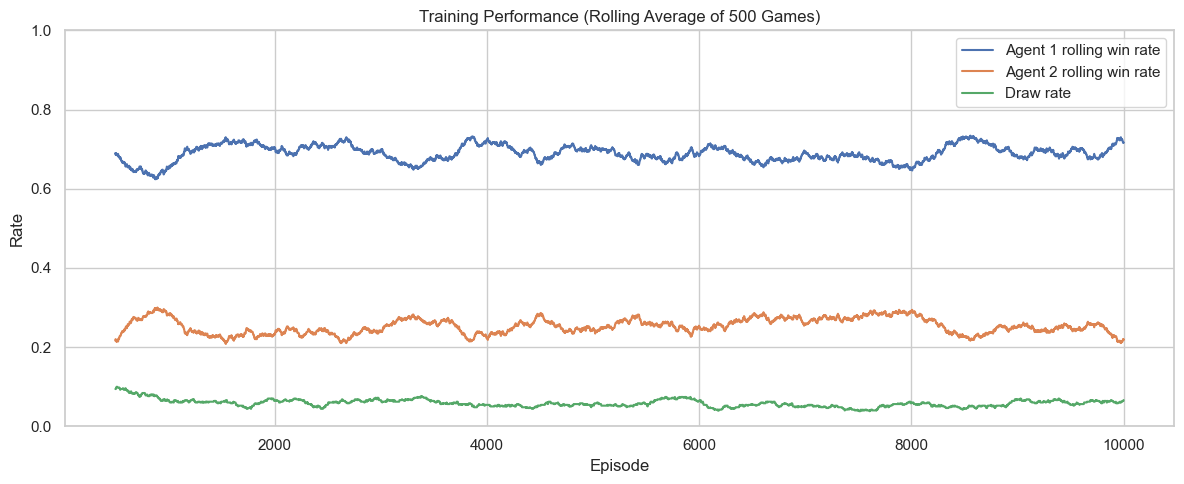

In [12]:
# VISUALIZATION 1: Training outcomes over episodes
window = 500
episode_numbers = np.arange(1, len(training_results) + 1)

agent1_training_wins = (training_results == 1).astype(int)
agent2_training_wins = (training_results == -1).astype(int)
training_draws = (training_results == 0).astype(int)

def rolling_rate(values, window):
    return np.convolve(values, np.ones(window) / window, mode="valid")

plt.figure(figsize=(12, 5))
plt.plot(
    np.arange(window, len(training_results) + 1),
    rolling_rate(agent1_training_wins, window),
    label="Agent 1 rolling win rate"
)
plt.plot(
    np.arange(window, len(training_results) + 1),
    rolling_rate(agent2_training_wins, window),
    label="Agent 2 rolling win rate"
)
plt.plot(
    np.arange(window, len(training_results) + 1),
    rolling_rate(training_draws, window),
    label="Draw rate"
)
plt.title(f"Training Performance (Rolling Average of {window} Games)")
plt.xlabel("Episode")
plt.ylabel("Rate")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()





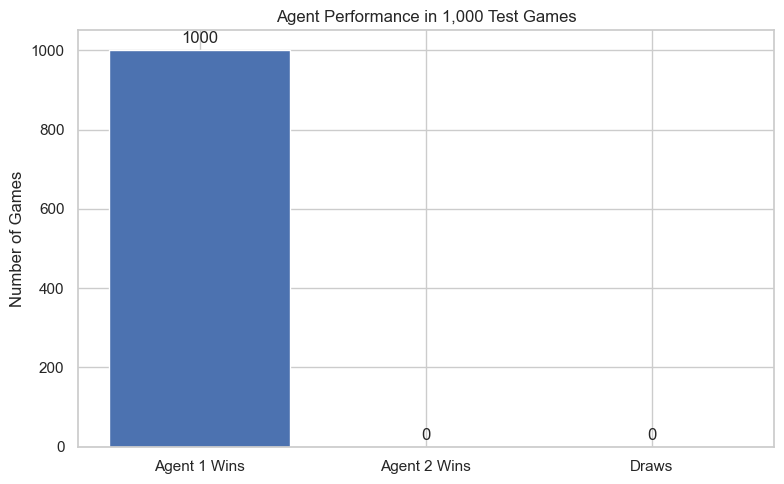

In [13]:
# VISUALIZATION 2: Final testing results - bar chart
result_labels = ["Agent 1 Wins", "Agent 2 Wins", "Draws"]
result_values = [agent1_wins, agent2_wins, draws]

plt.figure(figsize=(8, 5))
bars = plt.bar(result_labels, result_values)
plt.title("Agent Performance in 1,000 Test Games")
plt.ylabel("Number of Games")
plt.bar_label(bars, padding=3)
plt.tight_layout()
plt.show()




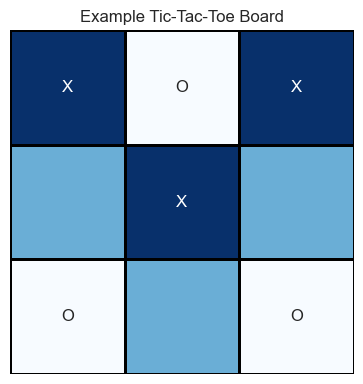

In [16]:
# VISUALIZATION 5: Example Tic-Tac-Toe board layout
example_board = np.array([
    [1, -1, 1],
    [0, 1, 0],
    [-1, 0, -1]
])

plt.figure(figsize=(4, 4))
sns.heatmap(
    example_board,
    annot=np.where(example_board == 1, "X",
                   np.where(example_board == -1, "O", "")),
    fmt="",
    cmap="Blues",
    cbar=False,
    linewidths=2,
    linecolor="black",
    square=True,
    xticklabels=False,
    yticklabels=False,
    vmin=-1,
    vmax=1
)
plt.title("Example Tic-Tac-Toe Board")
plt.tight_layout()
plt.show()